# UPI and India's digital payments: exploratory analysis (Unit 1)

**Question:** How has UPI's share of India's digital payments changed over time?

**Data:** RBI Payment System Indicators and NPCI UPI statistics, cleaned by `data/clean_data.py` (`data/clean/`).
**Outputs:** `exports/eda_metrics.csv`, `exports/key_insights.csv`, and six PNG charts in `exports/figures/`.

**Sections:** 1. Load and contract check · 2. Data quality · 3. Metrics pipeline · 4. Core question · 5. Statistics · 6. Charts · 7. Exports · 8. Final validation

**Scope note:** "UPI share" means UPI divided by the seven payment methods in the dataset (UPI, IMPS, NEFT, RTGS, debit card, credit card, NACH). It is not a share of every digital payment instrument that RBI reports.

## 1. Load and contract check

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data" / "clean"
EXPORT_DIR = ROOT / "exports"
FIG_DIR = EXPORT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Analysis settings (change here, re-run all)
Z_THRESHOLD = 2.5      # anomaly rule: |z-score of MoM volume growth| above this, per payment method
TREND_WINDOW = 3       # months averaged for trend_label
TREND_BAND = 1.0       # % per month: above = Increasing, below -band = Decreasing

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

payments = pd.read_csv(DATA_DIR / "fact_payments_monthly.csv", parse_dates=["date"])
upi = pd.read_csv(DATA_DIR / "upi_monthly_detail.csv", parse_dates=["date"])
dim_date = pd.read_csv(DATA_DIR / "dim_date.csv", parse_dates=["date"])

CONTRACT = {
    "fact_payments_monthly": (payments, ["date", "payment_method", "volume_mn", "value_cr"]),
    "upi_monthly_detail": (upi, ["date", "banks_live", "volume_mn", "value_cr", "avg_ticket_inr"]),
    "dim_date": (dim_date, ["date", "year", "fy", "quarter", "month_num", "month_name"]),
}
for name, (df, cols) in CONTRACT.items():
    missing = set(cols) - set(df.columns)
    assert not missing, f"{name} is missing contract columns: {missing}"
    print(f"{name:<24} rows={len(df):>4}  columns OK")

print("\nPeriod:", payments["date"].min().date(), "to", payments["date"].max().date())
print("Methods:", sorted(payments["payment_method"].unique()))

fact_payments_monthly    rows= 168  columns OK
upi_monthly_detail       rows=  24  columns OK
dim_date                 rows=  24  columns OK

Period: 2023-04-01 to 2025-03-01
Methods: ['Credit Card', 'Debit Card', 'IMPS', 'NACH', 'NEFT', 'RTGS', 'UPI']


## 2. Data quality
Structural checks must pass. The cross-source checks report differences instead of stopping the run.

In [2]:
methods = sorted(payments["payment_method"].unique())
n_months = payments["date"].nunique()
month_steps = payments["date"].drop_duplicates().sort_values().diff().dropna().dt.days

quality = pd.Series({
    "no duplicate (date, method) rows": not payments.duplicated(["date", "payment_method"]).any(),
    "complete grid (every method, every month)": len(payments) == len(methods) * n_months,
    "no missing values": bool(payments.notna().all().all()),
    "no negative volume or value": bool((payments[["volume_mn", "value_cr"]] >= 0).all().all()),
    "all dates are the 1st of a month": bool((payments["date"].dt.day == 1).all()),
    "no gaps between months": bool(month_steps.between(28, 31).all()),
    "dim_date covers every month": set(payments["date"]) <= set(dim_date["date"]),
    "UPI detail has one row per month": not upi.duplicated("date").any() and len(upi) == n_months,
}, name="passed")
print(quality.to_string())
assert quality.all(), "A structural check failed: fix the data before going on."

no duplicate (date, method) rows             True
complete grid (every method, every month)    True
no missing values                            True
no negative volume or value                  True
all dates are the 1st of a month             True
no gaps between months                       True
dim_date covers every month                  True
UPI detail has one row per month             True


In [3]:
# Cross-source check: UPI rows in the fact table vs NPCI detail file, and ticket-size formula vs the file's own column
fact_upi = payments.loc[payments["payment_method"] == "UPI", ["date", "volume_mn", "value_cr"]]
x = fact_upi.merge(upi, on="date", suffixes=("_fact", "_npci"))
x["vol_diff_pct"] = (x["volume_mn_fact"] / x["volume_mn_npci"] - 1) * 100
x["val_diff_pct"] = (x["value_cr_fact"] / x["value_cr_npci"] - 1) * 100
x["ticket_recalc"] = x["value_cr_npci"] * 1e7 / (x["volume_mn_npci"] * 1e6)
x["ticket_diff_inr"] = x["ticket_recalc"] - x["avg_ticket_inr"]

print("Months compared:", len(x))
print(f"Max |volume difference|: {x['vol_diff_pct'].abs().max():.4f}%")
print(f"Max |value difference|:  {x['val_diff_pct'].abs().max():.4f}%")
print(f"Max |ticket formula difference|: INR {x['ticket_diff_inr'].abs().max():.6f}")

# Results of verify_upi_sources.py / verify_rbi_extraction.py, if they have been run
for fname in ["upi_source_comparison.csv", "rbi_extraction_comparison.csv"]:
    p = DATA_DIR / fname
    if p.exists():
        c = pd.read_csv(p)
        diffs = {col: round(float(c[col].abs().max()), 6) for col in c.columns if col.endswith("difference")}
        print(f"{fname}: max absolute differences {diffs}")
    else:
        print(f"{fname}: not found (run the matching verify script to add this check)")

Months compared: 24
Max |volume difference|: 0.0000%
Max |value difference|:  0.0000%
Max |ticket formula difference|: INR 0.000000
upi_source_comparison.csv: not found (run the matching verify script to add this check)
rbi_extraction_comparison.csv: not found (run the matching verify script to add this check)


## 3. Metrics pipeline

One function per metric, each reading the contract columns and adding output columns.

**Anomaly rule.** For each payment method, compute the z-score of its month-on-month volume growth and flag months where |z| is above `Z_THRESHOLD` (2.5). A 3σ rule is too strict here: with only 23 growth values per method, almost nothing can reach it. The sensitivity table below shows how many months each threshold flags. A flag marks an unusual month, not an error. `anomaly_reason` only names a calendar coincidence (fiscal year-end or start) and otherwise says `unexplained`.

**Trend label.** Single-month growth is noisy (February is shorter, March has year-end effects), so the label uses the average MoM growth of the last 3 months. The first month of each method has no growth rate and is labelled `Insufficient data`.

In [4]:
CALENDAR_NOTES = {
    3: "coincides with fiscal year-end (March)",
    4: "coincides with start of the new fiscal year (April)",
}

def add_totals(df):
    out = df.copy()
    out["total_volume_mn"] = out.groupby("date")["volume_mn"].transform("sum")
    out["total_value_cr"] = out.groupby("date")["value_cr"].transform("sum")
    return out

def add_growth(df):
    out = df.sort_values(["payment_method", "date"]).copy()
    g = out.groupby("payment_method")
    out["mom_vol_pct"] = (out["volume_mn"] / g["volume_mn"].shift(1) - 1) * 100
    out["yoy_vol_pct"] = (out["volume_mn"] / g["volume_mn"].shift(12) - 1) * 100
    out["yoy_val_pct"] = (out["value_cr"] / g["value_cr"].shift(12) - 1) * 100
    return out

def add_share(df):
    out = df.copy()
    out["share_vol_pct"] = out["volume_mn"] / out["total_volume_mn"] * 100
    out["share_val_pct"] = out["value_cr"] / out["total_value_cr"] * 100
    return out

def add_ticket(df):
    out = df.copy()
    out["avg_ticket_inr"] = (out["value_cr"] * 1e7 / (out["volume_mn"] * 1e6)).where(out["volume_mn"] > 0)
    return out

def flag_anomalies(df, z=Z_THRESHOLD):
    out = df.copy()
    grp = out.groupby("payment_method")["mom_vol_pct"]
    out["mom_z"] = (out["mom_vol_pct"] - grp.transform("mean")) / grp.transform("std")
    out["is_anomaly"] = (out["mom_z"].abs() > z).astype(int)

    def reason(row):
        if row["is_anomaly"] == 0:
            return ""
        note = CALENDAR_NOTES.get(row["date"].month, "unexplained")
        return f"MoM volume {row['mom_vol_pct']:+.1f}% (z={row['mom_z']:+.2f}); {note}"

    out["anomaly_reason"] = out.apply(reason, axis=1)
    return out

def add_trend_label(df, window=TREND_WINDOW, band=TREND_BAND):
    out = df.copy()
    smooth = out.groupby("payment_method")["mom_vol_pct"].transform(
        lambda s: s.rolling(window, min_periods=1).mean()
    )
    out["trend_label"] = np.select([smooth > band, smooth < -band], ["Increasing", "Decreasing"], default="Stable")
    out.loc[smooth.isna(), "trend_label"] = "Insufficient data"
    return out

fy_map = dim_date.set_index("date")["fy"]

metrics = (
    payments.pipe(add_totals).pipe(add_growth).pipe(add_share)
            .pipe(add_ticket).pipe(flag_anomalies).pipe(add_trend_label)
)
metrics["fy"] = metrics["date"].map(fy_map)

print("Rows:", len(metrics))
print("Anomalies flagged:", int(metrics["is_anomaly"].sum()))
print("\nTrend labels:\n" + metrics["trend_label"].value_counts().to_string())

Rows: 168
Anomalies flagged: 2

Trend labels:
trend_label
Increasing           96
Decreasing           41
Stable               24
Insufficient data     7


In [5]:
# Sensitivity of the anomaly rule to its threshold
rows = []
for z in (2.0, 2.5, 3.0):
    flagged = flag_anomalies(metrics, z=z)
    rows.append({"threshold (sigma)": z, "months flagged": int(flagged["is_anomaly"].sum())})
print(pd.DataFrame(rows).to_string(index=False))
print(f"\nLargest |z| for any method: {metrics['mom_z'].abs().max():.2f}")

print(f"\nFlagged at {Z_THRESHOLD} sigma:")
display(
    metrics.loc[metrics["is_anomaly"] == 1, ["date", "payment_method", "mom_vol_pct", "mom_z", "anomaly_reason"]]
           .sort_values("date").reset_index(drop=True)
)

 threshold (sigma)  months flagged
               2.0               6
               2.5               2
               3.0               0

Largest |z| for any method: 2.79

Flagged at 2.5 sigma:


,date,payment_method,mom_vol_pct,mom_z,anomaly_reason
0,2024-04-01,NACH,-25.518146,-2.789560,MoM volume -25.5% (z=-2.79); coincides with st...
1,2025-03-01,RTGS,25.727395,2.534879,MoM volume +25.7% (z=+2.53); coincides with fi...


## 4. Core question: how has UPI's share changed?

In [6]:
share_vol = metrics.pivot(index="date", columns="payment_method", values="share_vol_pct")
share_val = metrics.pivot(index="date", columns="payment_method", values="share_val_pct")

upi_m = metrics[metrics["payment_method"] == "UPI"].sort_values("date").reset_index(drop=True)
first, last = upi_m.iloc[0], upi_m.iloc[-1]

print(f"UPI volume share: {first.share_vol_pct:.2f}% ({first.date:%b %Y}) -> {last.share_vol_pct:.2f}% ({last.date:%b %Y}), "
      f"change {last.share_vol_pct - first.share_vol_pct:+.2f} pts")
print(f"UPI value share:  {first.share_val_pct:.2f}% -> {last.share_val_pct:.2f}%, "
      f"change {last.share_val_pct - first.share_val_pct:+.2f} pts "
      f"(range {upi_m.share_val_pct.min():.2f}% to {upi_m.share_val_pct.max():.2f}%)")

fy_share = upi_m.groupby("fy")[["share_vol_pct", "share_val_pct", "avg_ticket_inr"]].mean().round(2)
print("\nUPI averages by financial year:")
print(fy_share.to_string())

# Where did the share come from?
delta_vol = (share_vol.iloc[-1] - share_vol.iloc[0]).sort_values()
print("\nChange in volume share by method (percentage points):")
print(delta_vol.round(2).to_string())

# Did UPI "overtake" other modes inside this window?
lead_vol = share_vol.idxmax(axis=1)
lead_val = share_val.idxmax(axis=1)
print(f"\nMonths in which UPI is the largest method by volume: {(lead_vol == 'UPI').sum()} of {len(lead_vol)}")
print(f"Largest method by value: {lead_val.value_counts().to_dict()}")
if (lead_vol == "UPI").all():
    print("-> UPI already leads by volume in the first month, so there is no crossover inside this window.")

UPI volume share: 83.81% (Apr 2023) -> 88.70% (Mar 2025), change +4.90 pts
UPI value share:  8.33% -> 8.25%, change -0.08 pts (range 7.46% to 10.04%)

UPI averages by financial year:
           share_vol_pct  share_val_pct  avg_ticket_inr
fy                                                     
FY2023-24          85.19           8.27         1528.62
FY2024-25          87.84           9.17         1404.64

Change in volume share by method (percentage points):
payment_method
IMPS          -2.45
Debit Card    -1.59
NACH          -0.39
Credit Card   -0.23
NEFT          -0.20
RTGS          -0.04
UPI            4.90

Months in which UPI is the largest method by volume: 24 of 24
Largest method by value: {'RTGS': 24}
-> UPI already leads by volume in the first month, so there is no crossover inside this window.


## 5. Statistics

* **CAGR** is the compound annual growth rate between the first and last month, annualised over the 23 months between them. Financial-year totals are shown as a cleaner comparison, since month endpoints are affected by seasonality.
* **Trend significance** uses the Mann-Kendall test (Kendall's tau against time, no autocorrelation correction), with the Theil-Sen slope for size and an OLS slope with p-value as a cross-check.
* **Volume vs value** is correlated on levels and on month-on-month growth, because two growing series correlate on levels almost automatically.

With only 24 monthly points these results describe this window; they are not a long-run forecast.

In [7]:
upi_raw = payments[payments["payment_method"] == "UPI"].sort_values("date").reset_index(drop=True)
upi_raw["fy"] = upi_raw["date"].map(fy_map)

# CAGR (endpoint to endpoint, annualised) and growth between financial years
years = (len(upi_raw) - 1) / 12
cagr_vol = ((upi_raw["volume_mn"].iloc[-1] / upi_raw["volume_mn"].iloc[0]) ** (1 / years) - 1) * 100
cagr_val = ((upi_raw["value_cr"].iloc[-1] / upi_raw["value_cr"].iloc[0]) ** (1 / years) - 1) * 100
total_growth_vol = (upi_raw["volume_mn"].iloc[-1] / upi_raw["volume_mn"].iloc[0] - 1) * 100
print(f"UPI volume: total growth {total_growth_vol:.1f}%, CAGR {cagr_vol:.1f}%")
print(f"UPI value:  CAGR {cagr_val:.1f}%")

fy_tot = upi_raw.groupby("fy").agg(months=("date", "count"), volume_mn=("volume_mn", "sum"), value_cr=("value_cr", "sum"))
print("\nFinancial-year totals:")
print(fy_tot.to_string())
if (fy_tot["months"] == 12).all() and len(fy_tot) >= 2:
    fy_names = list(fy_tot.index)
    fy_vol_growth = (fy_tot["volume_mn"].iloc[-1] / fy_tot["volume_mn"].iloc[-2] - 1) * 100
    fy_val_growth = (fy_tot["value_cr"].iloc[-1] / fy_tot["value_cr"].iloc[-2] - 1) * 100
    print(f"{fy_names[-1]} vs {fy_names[-2]}: volume {fy_vol_growth:+.1f}%, value {fy_val_growth:+.1f}%")

# Trend tests
t = np.arange(len(upi_m))
def trend_row(name, y):
    y = np.asarray(y, dtype=float)
    tau, p_mk = stats.kendalltau(t, y)
    sen = stats.theilslopes(y, t)
    ols = stats.linregress(t, y)
    return {"series": name, "kendall_tau": tau, "mann_kendall_p": p_mk,
            "theil_sen_slope/month": sen[0], "ols_slope/month": ols.slope, "ols_p": ols.pvalue, "r_squared": ols.rvalue ** 2}

trend_table = pd.DataFrame([
    trend_row("UPI volume (mn)", upi_raw["volume_mn"]),
    trend_row("UPI volume share (%)", upi_m["share_vol_pct"]),
    trend_row("UPI value share (%)", upi_m["share_val_pct"]),
    trend_row("UPI avg ticket (INR)", upi_m["avg_ticket_inr"]),
]).set_index("series")
print("\nTrend tests (24 monthly points):")
print(trend_table.round(4).to_string())

# Volume vs value
vol, val = upi_raw["volume_mn"].to_numpy(), upi_raw["value_cr"].to_numpy()
r_lvl, p_lvl = stats.pearsonr(vol, val)
rho_lvl, _ = stats.spearmanr(vol, val)
g_vol, g_val = pd.Series(vol).pct_change().dropna(), pd.Series(val).pct_change().dropna()
r_gr, p_gr = stats.pearsonr(g_vol, g_val)
print(f"\nVolume vs value, levels: Pearson r={r_lvl:.3f} (p={p_lvl:.2g}), Spearman rho={rho_lvl:.3f}")
print(f"Volume vs value, MoM growth: Pearson r={r_gr:.3f} (p={p_gr:.2g})")

UPI volume: total growth 106.5%, CAGR 46.0%
UPI value:  CAGR 33.9%

Financial-year totals:
           months  volume_mn     value_cr
fy                                       
FY2023-24      12  131129.83  19995085.51
FY2024-25      12  185866.02  26056954.65
FY2024-25 vs FY2023-24: volume +41.7%, value +30.3%

Trend tests (24 monthly points):
                      kendall_tau  mann_kendall_p  theil_sen_slope/month  ols_slope/month   ols_p  r_squared
series                                                                                                      
UPI volume (mn)            0.9275          0.0000               380.2666         380.2064  0.0000     0.9762
UPI volume share (%)       0.9493          0.0000                 0.2145           0.2156  0.0000     0.9763
UPI value share (%)        0.4565          0.0014                 0.0653           0.0585  0.0011     0.3894
UPI avg ticket (INR)      -0.8116          0.0000               -10.3608         -10.0231  0.0000     0.9054



## 6. Charts 

saved exports\figures\01_upi_volume_value.png


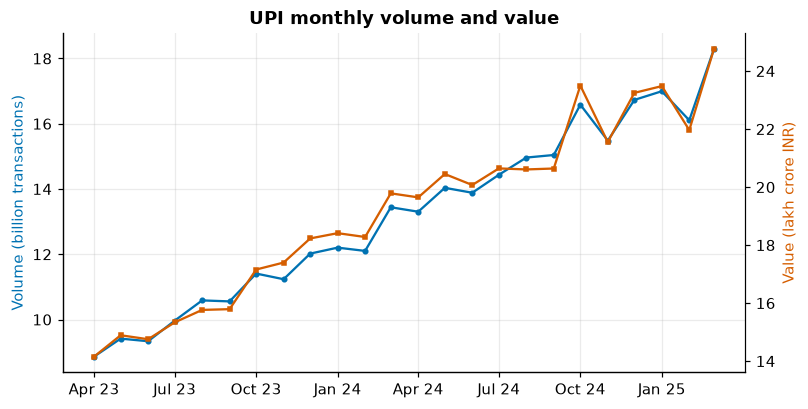

saved exports\figures\02_volume_share_by_method.png


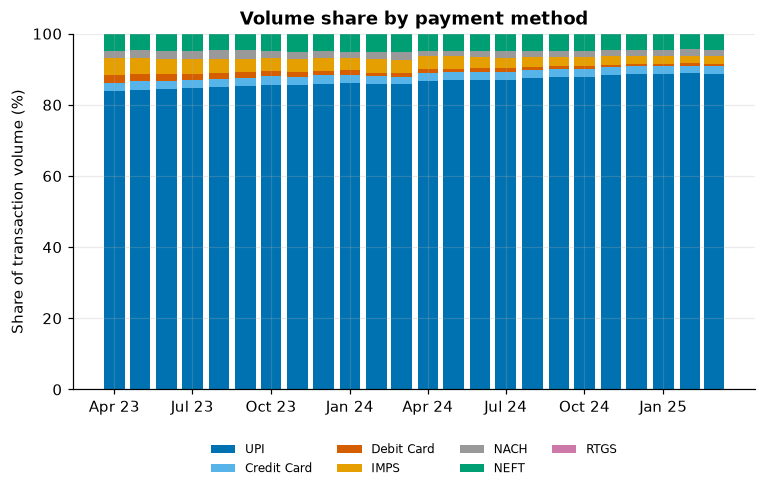

saved exports\figures\03_upi_share_volume_vs_value.png


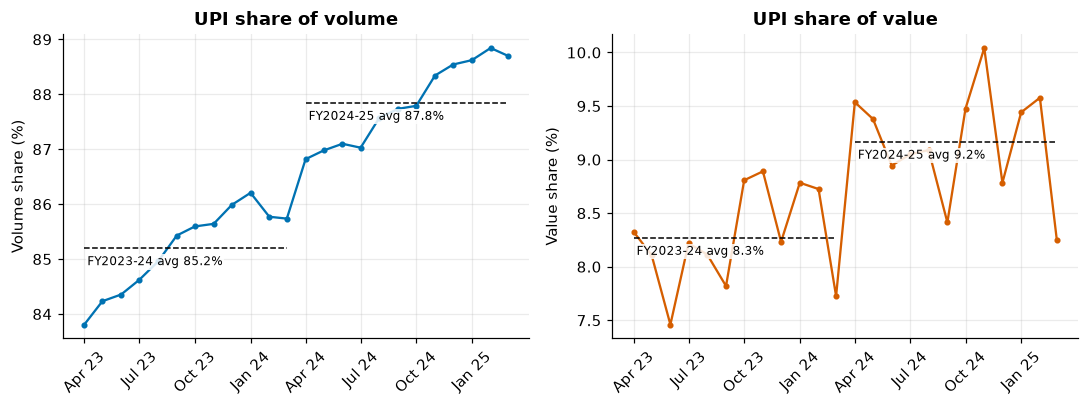

saved exports\figures\04_upi_yoy_growth.png


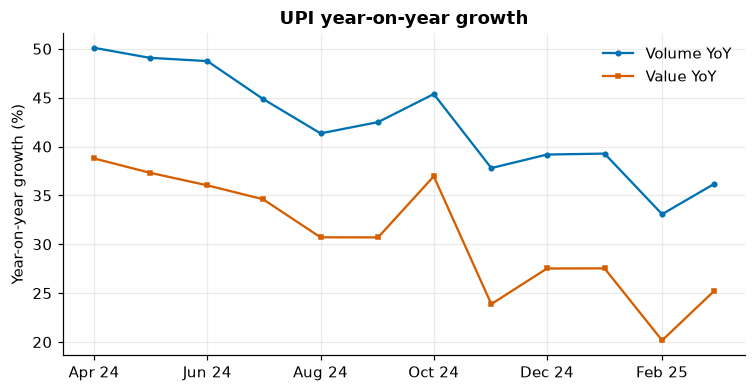

saved exports\figures\05_upi_ticket_size.png


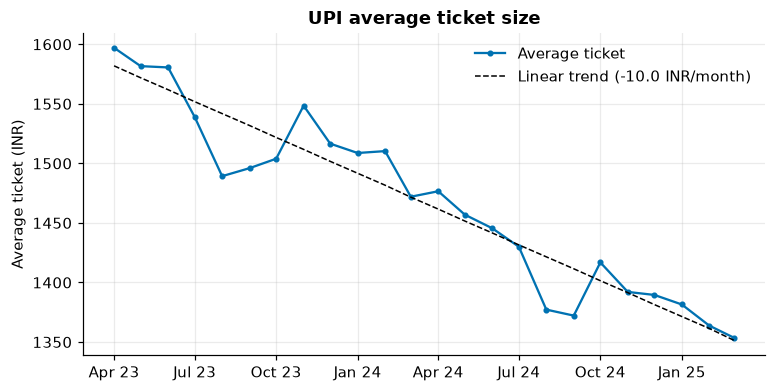

saved exports\figures\06_mom_growth_heatmap.png


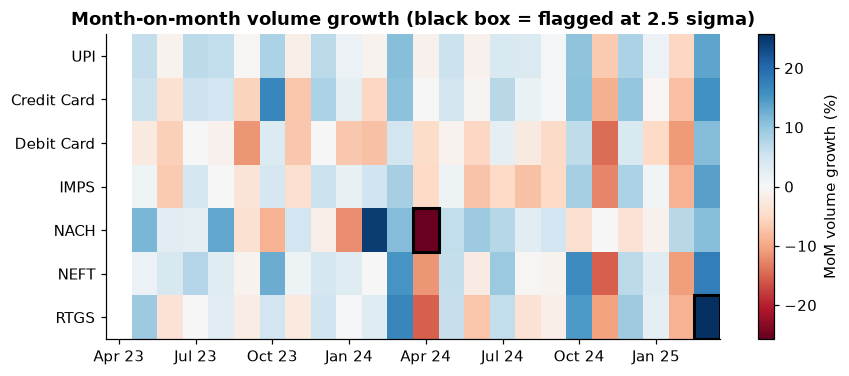

In [8]:
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 10, "axes.titleweight": "bold",
})
PALETTE = {"UPI": "#0072B2", "IMPS": "#E69F00", "NEFT": "#009E73", "RTGS": "#CC79A7",
           "Debit Card": "#D55E00", "Credit Card": "#56B4E9", "NACH": "#999999"}
UPI_C, ACCENT = "#0072B2", "#D55E00"

def save_fig(fig, name):
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, bbox_inches="tight")
    print("saved", path.relative_to(ROOT))
    plt.show()

dates = upi_m["date"]
tick_pos = dates[::3]
tick_lbl = [d.strftime("%b %y") for d in tick_pos]

# 1. UPI volume and value
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(dates, upi_raw["volume_mn"] / 1000, color=UPI_C, marker="o", ms=3, label="Volume (bn transactions)")
ax1.set_ylabel("Volume (billion transactions)", color=UPI_C)
ax2 = ax1.twinx()
ax2.plot(dates, upi_raw["value_cr"] / 1e5, color=ACCENT, marker="s", ms=3, label="Value (lakh crore INR)")
ax2.set_ylabel("Value (lakh crore INR)", color=ACCENT)
ax2.grid(False); ax2.spines["right"].set_visible(True)
ax1.set_xticks(tick_pos); ax1.set_xticklabels(tick_lbl)
ax1.set_title("UPI monthly volume and value")
save_fig(fig, "01_upi_volume_value")

# 2. Volume share by method (100% stacked)
order = ["UPI"] + [m for m in share_vol.columns if m != "UPI"]
fig, ax = plt.subplots(figsize=(8, 4.2))
bottom = np.zeros(len(share_vol))
for m in order:
    ax.bar(share_vol.index, share_vol[m], bottom=bottom, width=24, color=PALETTE.get(m, "#777"), label=m)
    bottom += share_vol[m].to_numpy()
ax.set_ylim(0, 100); ax.set_ylabel("Share of transaction volume (%)")
ax.set_xticks(tick_pos); ax.set_xticklabels(tick_lbl)
ax.legend(ncol=4, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)
ax.set_title("Volume share by payment method")
save_fig(fig, "02_volume_share_by_method")

# 3. UPI volume share and value share
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, col, label, c in [(axes[0], "share_vol_pct", "Volume share (%)", UPI_C),
                          (axes[1], "share_val_pct", "Value share (%)", ACCENT)]:
    ax.plot(dates, upi_m[col], color=c, marker="o", ms=3)
    for fy_name, g in upi_m.groupby("fy"):
        ax.hlines(g[col].mean(), g["date"].min(), g["date"].max(), colors="k", linestyles="--", lw=1)
        ax.annotate(f"{fy_name} avg {g[col].mean():.1f}%", (g["date"].min(), g[col].mean()), xytext=(2, -11),
                    textcoords="offset points", fontsize=8, bbox=dict(fc="white", ec="none", alpha=0.85, pad=1))
    ax.set_ylabel(label); ax.set_xticks(tick_pos); ax.set_xticklabels(tick_lbl, rotation=45)
axes[0].set_title("UPI share of volume"); axes[1].set_title("UPI share of value")
fig.tight_layout()
save_fig(fig, "03_upi_share_volume_vs_value")

# 4. UPI year-on-year growth
yoy = upi_m.dropna(subset=["yoy_vol_pct"])
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(yoy["date"], yoy["yoy_vol_pct"], color=UPI_C, marker="o", ms=3, label="Volume YoY")
ax.plot(yoy["date"], yoy["yoy_val_pct"], color=ACCENT, marker="s", ms=3, label="Value YoY")
ax.set_ylabel("Year-on-year growth (%)"); ax.legend(frameon=False)
ax.set_title("UPI year-on-year growth")
ax.set_xticks(yoy["date"][::2]); ax.set_xticklabels([d.strftime("%b %y") for d in yoy["date"][::2]])
save_fig(fig, "04_upi_yoy_growth")

# 5. Average ticket size with linear trend
slope, intercept = np.polyfit(t, upi_m["avg_ticket_inr"], 1)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(dates, upi_m["avg_ticket_inr"], color=UPI_C, marker="o", ms=3, label="Average ticket")
ax.plot(dates, intercept + slope * t, "k--", lw=1, label=f"Linear trend ({slope:+.1f} INR/month)")
ax.set_ylabel("Average ticket (INR)"); ax.legend(frameon=False)
ax.set_xticks(tick_pos); ax.set_xticklabels(tick_lbl)
ax.set_title("UPI average ticket size")
save_fig(fig, "05_upi_ticket_size")

# 6. MoM volume growth heatmap with flagged months outlined
mom = metrics.pivot(index="payment_method", columns="date", values="mom_vol_pct").reindex(order)
flag = metrics.pivot(index="payment_method", columns="date", values="is_anomaly").reindex(order)
lim = float(np.nanmax(np.abs(mom.to_numpy())))
fig, ax = plt.subplots(figsize=(9, 3.6))
im = ax.imshow(mom.to_numpy(), cmap="RdBu", vmin=-lim, vmax=lim, aspect="auto")
for i in range(flag.shape[0]):
    for j in range(flag.shape[1]):
        if flag.iloc[i, j] == 1:
            ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec="black", lw=2))
ax.set_yticks(range(len(mom.index))); ax.set_yticklabels(mom.index)
ax.set_xticks(range(0, len(mom.columns), 3)); ax.set_xticklabels([d.strftime("%b %y") for d in mom.columns[::3]])
ax.grid(False)
fig.colorbar(im, ax=ax, label="MoM volume growth (%)")
ax.set_title(f"Month-on-month volume growth (black box = flagged at {Z_THRESHOLD} sigma)")
save_fig(fig, "06_mom_growth_heatmap")

## 7. Exports

In [9]:
EDA_COLUMNS = ["date", "payment_method", "mom_vol_pct", "yoy_vol_pct", "yoy_val_pct",
               "share_vol_pct", "share_val_pct", "avg_ticket_inr", "is_anomaly", "anomaly_reason", "trend_label"]

eda_metrics = metrics[EDA_COLUMNS].copy()
eda_metrics["date"] = eda_metrics["date"].dt.strftime("%Y-%m-%d")
eda_metrics.to_csv(EXPORT_DIR / "eda_metrics.csv", index=False)
print("Saved", (EXPORT_DIR / "eda_metrics.csv").relative_to(ROOT), eda_metrics.shape)

# ---- key insights: every number below is computed from the data above ----
fy_first, fy_last = fy_share.index[0], fy_share.index[-1]
gain_pts = last.share_vol_pct - first.share_vol_pct
losers = delta_vol.drop("UPI").head(2)          # delta_vol is sorted ascending: biggest losers first
top_val_method = share_val.mean().idxmax()
top_val_share = share_val.mean().max()
yoy_first, yoy_last = yoy["yoy_vol_pct"].iloc[0], yoy["yoy_vol_pct"].iloc[-1]
ticket_pct = (last.avg_ticket_inr / first.avg_ticket_inr - 1) * 100
period = f"{first.date:%b %Y} to {last.date:%b %Y}"

insights = pd.DataFrame([
    {"order": 1, "stage": "hook",
     "headline": f"UPI now carries {last.share_vol_pct:.1f}% of transactions",
     "detail": f"In {last.date:%b %Y}, UPI handled {last.share_vol_pct:.1f}% of the volume across the seven payment methods in the dataset.",
     "metric_value": round(last.share_vol_pct, 2), "metric_label": f"UPI volume share, {last.date:%b %Y} (%)"},
    {"order": 2, "stage": "buildup",
     "headline": f"UPI gained {gain_pts:.1f} points of volume share in two years",
     "detail": (f"Share rose from {first.share_vol_pct:.1f}% to {last.share_vol_pct:.1f}% ({period}), taken mainly from "
                f"{losers.index[0]} ({losers.iloc[0]:+.1f} pts) and {losers.index[1]} ({losers.iloc[1]:+.1f} pts)."),
     "metric_value": round(gain_pts, 2), "metric_label": "UPI volume share change (pts)"},
    {"order": 3, "stage": "buildup",
     "headline": f"UPI volume grew {total_growth_vol:.0f}% over the period",
     "detail": f"Monthly UPI transactions grew from {upi_raw['volume_mn'].iloc[0]:,.0f} mn to {upi_raw['volume_mn'].iloc[-1]:,.0f} mn, a compound annual rate of {cagr_vol:.1f}%.",
     "metric_value": round(total_growth_vol, 2), "metric_label": "UPI volume growth over the period (%)"},
    {"order": 4, "stage": "insight",
     "headline": "Volume dominance is not value dominance",
     "detail": (f"UPI averaged {fy_share.loc[fy_last, 'share_val_pct']:.1f}% of value in {fy_last} ({fy_share.loc[fy_first, 'share_val_pct']:.1f}% in {fy_first}), "
                f"while {top_val_method} carried {top_val_share:.0f}% of value on average."),
     "metric_value": round(float(fy_share.loc[fy_last, "share_val_pct"]), 2), "metric_label": f"UPI value share, {fy_last} average (%)"},
    {"order": 5, "stage": "conclusion",
     "headline": "Growth is maturing while tickets shrink",
     "detail": (f"UPI year-on-year volume growth slowed from {yoy_first:.1f}% to {yoy_last:.1f}%, "
                f"and the average ticket fell {abs(ticket_pct):.1f}% (INR {first.avg_ticket_inr:,.0f} to INR {last.avg_ticket_inr:,.0f})."),
     "metric_value": round(yoy_last, 2), "metric_label": f"UPI YoY volume growth, {last.date:%b %Y} (%)"},
])
insights.to_csv(EXPORT_DIR / "key_insights.csv", index=False)
print("Saved", (EXPORT_DIR / "key_insights.csv").relative_to(ROOT), insights.shape)
display(insights[["order", "stage", "headline", "metric_value", "metric_label"]])
for _, r in insights.iterrows():
    print(f"[{r['stage']}] {r['detail']}")

Saved exports\eda_metrics.csv (168, 11)
Saved exports\key_insights.csv (5, 6)


,order,stage,headline,metric_value,metric_label
0,1,hook,UPI now carries 88.7% of transactions,88.70,"UPI volume share, Mar 2025 (%)"
1,2,buildup,UPI gained 4.9 points of volume share in two y...,4.90,UPI volume share change (pts)
2,3,buildup,UPI volume grew 106% over the period,106.49,UPI volume growth over the period (%)
3,4,insight,Volume dominance is not value dominance,9.17,"UPI value share, FY2024-25 average (%)"
4,5,conclusion,Growth is maturing while tickets shrink,36.17,"UPI YoY volume growth, Mar 2025 (%)"


[hook] In Mar 2025, UPI handled 88.7% of the volume across the seven payment methods in the dataset.
[buildup] Share rose from 83.8% to 88.7% (Apr 2023 to Mar 2025), taken mainly from IMPS (-2.5 pts) and Debit Card (-1.6 pts).
[buildup] Monthly UPI transactions grew from 8,863 mn to 18,302 mn, a compound annual rate of 46.0%.
[insight] UPI averaged 9.2% of value in FY2024-25 (8.3% in FY2023-24), while RTGS carried 71% of value on average.
[conclusion] UPI year-on-year volume growth slowed from 50.1% to 36.2%, and the average ticket fell 15.2% (INR 1,597 to INR 1,354).


## 8. Final validation
Reloads the saved files and re-derives each insight number from the exported `eda_metrics.csv` (or the raw fact table), so every number traces back to this notebook.

In [10]:
eda_chk = pd.read_csv(EXPORT_DIR / "eda_metrics.csv", parse_dates=["date"])
ki_chk = pd.read_csv(EXPORT_DIR / "key_insights.csv")

# Structure
assert list(eda_chk.columns) == EDA_COLUMNS, "eda_metrics columns differ from CONTRACT.md"
assert list(ki_chk.columns) == ["order", "stage", "headline", "detail", "metric_value", "metric_label"]
assert len(eda_chk) == len(methods) * n_months, "unexpected row count"
assert not eda_chk.duplicated(["date", "payment_method"]).any()
assert eda_chk[["date", "payment_method", "share_vol_pct", "share_val_pct", "avg_ticket_inr", "trend_label"]].notna().all().all()
assert set(eda_chk["is_anomaly"].unique()) <= {0, 1}
assert set(eda_chk["trend_label"].unique()) <= {"Increasing", "Decreasing", "Stable", "Insufficient data"}
assert np.allclose(eda_chk.groupby("date")["share_vol_pct"].sum(), 100)
assert np.allclose(eda_chk.groupby("date")["share_val_pct"].sum(), 100)
assert (eda_chk.loc[eda_chk["is_anomaly"] == 1, "anomaly_reason"].notna()).all()

# Story shape and numbers
story_order = {"hook": 0, "buildup": 1, "insight": 2, "conclusion": 3}
stages = ki_chk["stage"].map(story_order)
assert stages.notna().all() and stages.is_monotonic_increasing, "stages must run hook -> buildup -> insight -> conclusion"
assert ki_chk["order"].tolist() == list(range(1, len(ki_chk) + 1))
assert 4 <= len(ki_chk) <= 6 and ki_chk["metric_value"].notna().all()

cu = eda_chk[eda_chk["payment_method"] == "UPI"].sort_values("date").copy()
cu["fy"] = cu["date"].map(fy_map)
fy_val = cu.groupby("fy")["share_val_pct"].mean()
raw_vol = payments.loc[payments["payment_method"] == "UPI"].sort_values("date")["volume_mn"]
expected = {
    1: cu["share_vol_pct"].iloc[-1],
    2: cu["share_vol_pct"].iloc[-1] - cu["share_vol_pct"].iloc[0],
    3: (raw_vol.iloc[-1] / raw_vol.iloc[0] - 1) * 100,
    4: fy_val.iloc[-1],
    5: cu["yoy_vol_pct"].dropna().iloc[-1],
}
got = ki_chk.set_index("order")["metric_value"]
for k, v in expected.items():
    assert abs(got[k] - v) < 0.006, f"insight {k}: file says {got[k]}, data says {v:.4f}"
print("All checks passed. Insight numbers re-derived from the exported data.")

print("\nFive UPI rows to spot-check against the Power BI dashboard:")
display(cu.sample(5, random_state=0).sort_values("date")[
    ["date", "share_vol_pct", "share_val_pct", "avg_ticket_inr", "yoy_vol_pct"]]
    .round({"share_vol_pct": 2, "share_val_pct": 2, "avg_ticket_inr": 2, "yoy_vol_pct": 2}))
print("\nExport files:")
for p in [EXPORT_DIR / "eda_metrics.csv", EXPORT_DIR / "key_insights.csv", *sorted(FIG_DIR.glob("*.png"))]:
    print(" ", p.relative_to(ROOT))

All checks passed. Insight numbers re-derived from the exported data.

Five UPI rows to spot-check against the Power BI dashboard:


,date,share_vol_pct,share_val_pct,avg_ticket_inr,yoy_vol_pct
154,2024-02-01,85.77,8.73,1510.30,NaN
155,2024-03-01,85.74,7.73,1471.99,NaN
158,2024-06-01,87.10,8.94,1445.49,48.74
164,2024-12-01,88.54,8.78,1389.54,39.18
166,2025-02-01,88.84,9.58,1363.75,33.08



Export files:
  exports\eda_metrics.csv
  exports\key_insights.csv
  exports\figures\01_upi_volume_value.png
  exports\figures\02_volume_share_by_method.png
  exports\figures\03_upi_share_volume_vs_value.png
  exports\figures\04_upi_yoy_growth.png
  exports\figures\05_upi_ticket_size.png
  exports\figures\06_mom_growth_heatmap.png


## Limitations

* The window is 24 months (Apr 2023 to Mar 2025), so year-on-year figures exist for only the last 12 months, and statistical tests rest on 24 points.
* UPI already leads by volume in the first month, so this window cannot show when UPI overtook other modes. That needs data from before April 2023.
* Shares are relative to the seven methods in the dataset, not to all RBI-reported digital payment instruments.
* Month-on-month volume is affected by month length and fiscal year-end effects. Anomaly flags mark unusual months and are not proof of data errors.